# AdaBoost for regression

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train an AdaBoost to predict the rent price of an apartment. We start with the default parameters, and then we change one component at a time, the number of trees, the loss function, the learning rate and the depth of the trees, so that we can see how each of them regulates the behaviour of the model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [4]:
# the trees from Scikit-learn take numbers, so we replace the categories by integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].apply(lambda var: var.astype("category").cat.codes)

# AdaBoost does not take missing values. From a theoretical perspective
# it could, but sklearn's implementation at the moment does not allow
# it. Maybe in future versions.
# For now, we replace NaN by a value outside the distribution.
df = df.fillna(-1)

df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,1,1.0,1.0,0,1,0,1191.0,800.0,101,10,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,1,2.0,4.0,0,2,0,1450.0,1880.0,1955,9,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,1,2.0,3.0,0,2,0,1395.0,1661.0,1955,9,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,1,2.0,3.0,0,2,0,1255.0,1400.0,1955,9,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,1,2.0,2.0,0,2,0,1693.0,1346.0,101,10,...,0,0,0,0,0,1,0,0,0,0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

In [10]:
# the mean rent price
y_train.mean(), y_test.mean()

(np.float64(1527.515742929929), np.float64(1526.5632805716957))

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on. When we leave the estimator empty, AdaBoost trains decision trees with a depth of three.

In [6]:
ada = AdaBoostRegressor(
    estimator=None,
    n_estimators=50,
    learning_rate=1.0,
    loss="linear",
    random_state=0,
)

ada.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
Name,Type,Value
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeRegressor,DecisionTreeR...r(max_depth=3)
estimator_errors_ estimator_errors_: ndarray of floatsRegression error for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[0.01,0.01,0.01,...,0.29,0.38,0.28]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[4.42,4.5 ,4.21,...,0.88,0.48,0.97]"
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators.,list,"[DecisionTreeR...ate=209652396), DecisionTreeR...tate=81001164), DecisionTreeR...ate=706712481), DecisionTreeR...te=1023250215), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](39,)","[0. ,0.09,0.11,...,0. ,0. ,0. ]"


In [7]:
def evaluate(model, X_train, y_train, X_test, y_test):
    for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        rmse = root_mean_squared_error(y, model.predict(X))
        r2 = r2_score(y, model.predict(X))
        print(f"{name} rmse: {rmse:.2f}, r2: {r2:.4f}")


evaluate(ada, X_train, y_train, X_test, y_test)

train rmse: 1150.39, r2: -0.5709
test rmse: 1158.67, r2: -0.7755


The r2 is negative, which means that this model is worse than predicting the average rent for every apartment, and the lowest prediction is far above the cheapest apartments of the test set.

In [8]:
# the model never predicts a cheap apartment
ada.predict(X_test).min().round(2), y_test.min()

(np.float64(1693.74), np.float64(200.0))

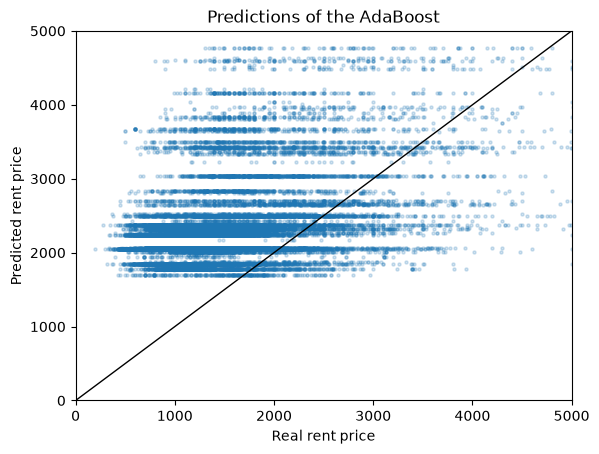

In [13]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = ada.predict(X_test)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of the AdaBoost")
plt.show()

First, we notice that these model outputs a piecewise function; it's not continuous. Second, it's obviously not doing a great job at predicting the rent prices. It makes the same piece prediction for a large range of rent values.

Let's now change one hyperparameter at a time to understand how they influence the model's behaviour.

### The number of trees

AdaBoost adds the trees one after the other, so we can evaluate the ensemble after each new tree with `staged_predict`, and we obtain the whole curve by training the model only once.

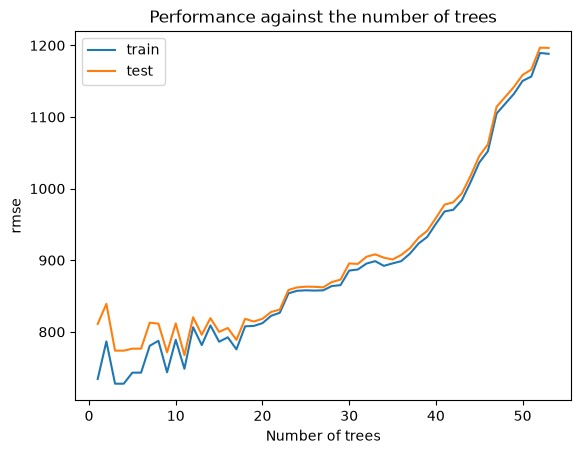

In [14]:
ada = AdaBoostRegressor(n_estimators=100, random_state=0)
ada.fit(X_train, y_train)

train_curve = [root_mean_squared_error(y_train, p) for p in ada.staged_predict(X_train)]
test_curve = [root_mean_squared_error(y_test, p) for p in ada.staged_predict(X_test)]

trees = range(1, len(train_curve) + 1)

plt.plot(trees, train_curve, label="train")
plt.plot(trees, test_curve, label="test")
plt.xlabel("Number of trees")
plt.ylabel("rmse")
plt.title("Performance against the number of trees")
plt.legend()
plt.show()

We see that more trees make the model worse, and this is the opposite of what we saw with the random forest, where more trees never hurt. In classification, adding more trees to AdaBoost also does not deteriorate performance, but for regression it does.

### The loss function

The loss decides how much extra weight an apartment receives when we predict it badly. The linear loss raises the weight in proportion to the error, the square loss raises it with the square of the error, and the exponential loss saturates, so that the worst apartments do not take over the whole ensemble.

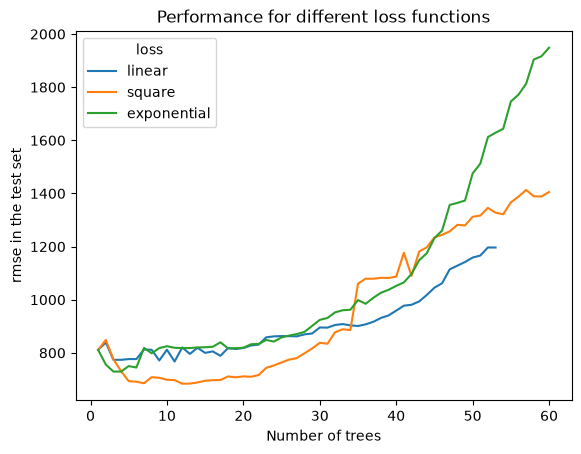

In [15]:
losses = ["linear", "square", "exponential"]

curves = {}
for loss in losses:
    model = AdaBoostRegressor(n_estimators=60, loss=loss, random_state=0)
    model.fit(X_train, y_train)
    curves[loss] = [root_mean_squared_error(y_test, p) for p in model.staged_predict(X_test)]

# AdaBoost stops adding trees when a tree becomes too weak, so some curves are shorter
curves = pd.DataFrame({key: pd.Series(values) for key, values in curves.items()})
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("rmse in the test set")
plt.title("Performance for different loss functions")
plt.legend(title="loss")
plt.show()

### The learning rate

The learning rate multiplies the contribution of each tree, so with a small learning rate every tree moves the ensemble a little and the weights of the apartments grow more slowly.

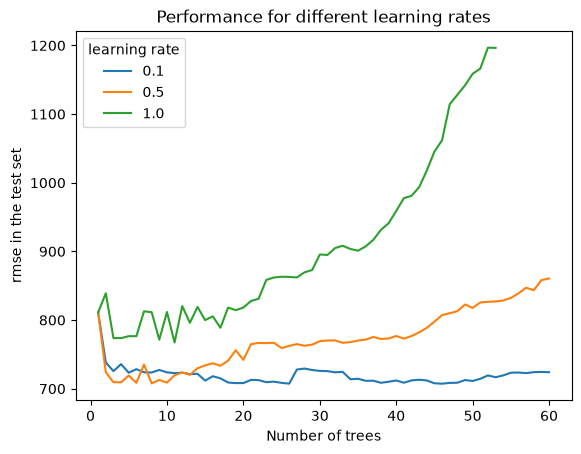

In [16]:
learning_rates = [0.1, 0.5, 1.0]

curves = {}
for learning_rate in learning_rates:
    model = AdaBoostRegressor(n_estimators=60, learning_rate=learning_rate, random_state=0)
    model.fit(X_train, y_train)
    curves[learning_rate] = [root_mean_squared_error(y_test, p) for p in model.staged_predict(X_test)]

# AdaBoost stops adding trees when a tree becomes too weak, so some curves are shorter
curves = pd.DataFrame({key: pd.Series(values) for key, values in curves.items()})
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("rmse in the test set")
plt.title("Performance for different learning rates")
plt.legend(title="learning rate")
plt.show()

We see that when the learning rate is large, the model deteriorates quite quickly. But with smaller learning rates, it continues to improve performance as we add more trees. So the learning rate is a very important hyperparameter in AdaBoost for regression.

### The depth of the trees

So far we used the trees that AdaBoost trains by default, which have a depth of three. Now we keep everything else fixed and we only change how deep each tree grows.

In [17]:
depths = [1, 3, 6, 10, 16]

results = {}
for depth in depths:
    model = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=depth),
        n_estimators=50,
        random_state=0,
    )
    model.fit(X_train, y_train)
    results[depth] = {
        "train": root_mean_squared_error(y_train, model.predict(X_train)),
        "test": root_mean_squared_error(y_test, model.predict(X_test)),
    }

results = pd.DataFrame(results).T
results.round(1)

,train,test
1,848.7,830.1
3,1150.4,1158.7
6,619.8,670.0
10,356.5,476.9
16,184.9,410.2


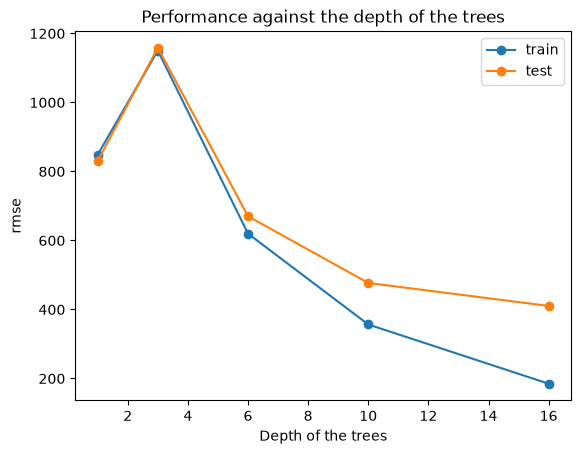

In [18]:
results.plot(marker="o")
plt.xlabel("Depth of the trees")
plt.ylabel("rmse")
plt.title("Performance against the depth of the trees")
plt.show()

The depth is another important hyperparameter for AdaBoost for regression. With shallow trees the model is not very good, but with deeper trees it becomes a reasonable model, because a deeper trees are able to capture the granularity of the target more effectively.

From here on we work with trees of depth eight.

In [19]:
ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=8),
    n_estimators=30,
    random_state=0,
)

ada.fit(X_train, y_train)

evaluate(ada, X_train, y_train, X_test, y_test)

train rmse: 441.21, r2: 0.7689
test rmse: 521.72, r2: 0.6400


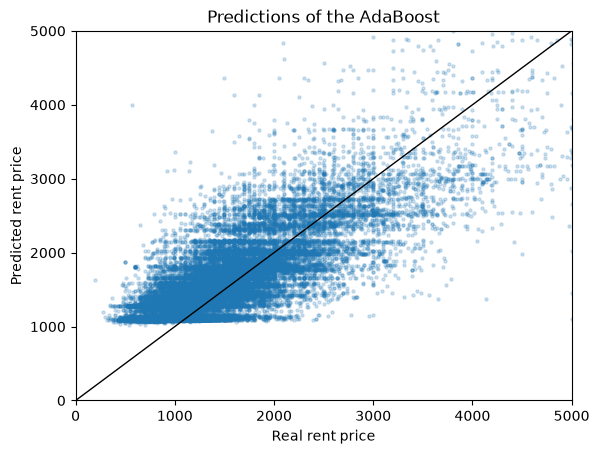

In [21]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = ada.predict(X_test)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of the AdaBoost")
plt.show()

## Optimising AdaBoost

We've seen that for regression, the hyperparameters of AdaBoost play an important role in controlling its performance. So let's go ahead and set up an automatic search for hyperparameters using randomised search.

In [22]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

In [23]:
# with a double underscore we reach the hyperparameters of the tree inside the ensemble
param_distributions = {
    "n_estimators": randint(20, 150),
    "learning_rate": loguniform(0.01, 1.0),
    "loss": ["linear", "square", "exponential"],
    "estimator__max_depth": randint(4, 20),
    "estimator__min_samples_leaf": randint(1, 50),
    "estimator__max_features": uniform(0.3, 0.7),
}

search = RandomizedSearchCV(
    AdaBoostRegressor(estimator=DecisionTreeRegressor(random_state=0), random_state=0),
    param_distributions,
    n_iter=60,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=0,
    n_jobs=-1,
)

search.fit(X_train, y_train)

search.best_params_

{'estimator__max_depth': 18,
 'estimator__max_features': np.float64(0.5899840961602689),
 'estimator__min_samples_leaf': 4,
 'learning_rate': np.float64(0.24262985503685788),
 'loss': 'linear',
 'n_estimators': 70}

In [24]:
# the standard deviation tells us how much the metric changes across the folds
results = pd.DataFrame(search.cv_results_)
results = results.sort_values("rank_test_score")

results[["mean_test_score", "std_test_score", "rank_test_score"]].head(10).round(2)

,mean_test_score,std_test_score,rank_test_score
16,-457.75,78.78,1
36,-458.13,74.09,2
52,-462.13,79.32,3
23,-464.33,79.05,4
30,-466.76,79.17,5
17,-468.82,84.08,6
0,-473.87,76.51,7
45,-477.23,76.89,8
10,-478.10,76.08,9
57,-484.72,77.80,10


In [25]:
evaluate(search.best_estimator_, X_train, y_train, X_test, y_test)

train rmse: 174.35, r2: 0.9639
test rmse: 401.75, r2: 0.7865


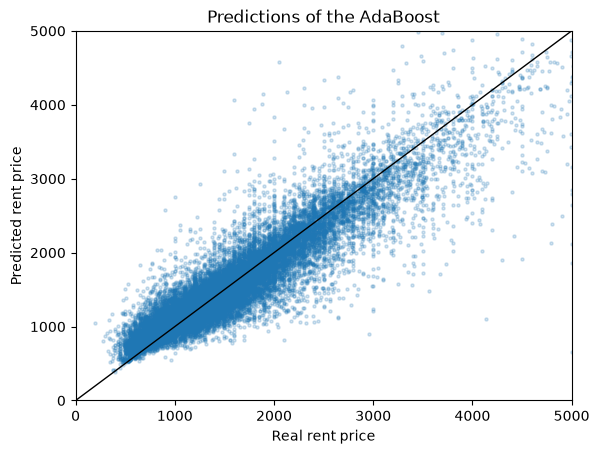

In [26]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = search.predict(X_test)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of the AdaBoost")
plt.show()

Now we are talking! As opposed to AdaBoost for classification, in regression, the single decision tree architecture plays an important role. This model makes a much better job at predicting rents. 

However, even though the model is better, there is still one important limitation for AdaBoost, which is that the model does not extrapolate, its output is constrained to the rent prices seen during training. Let's take a look at that.

### AdaBoost does not extrapolate

Every tree returns the average price of the apartments of a leaf, and AdaBoost returns one of those values, so the model can only ever answer with prices that it saw during training. To see this, we train a model with the small apartments only, and then we ask it for the price of apartments of any size.

In [28]:
# we'll reduce the training set to the smallest apartments
small_apartments = X_train["square_feet"] < 1200

limited = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=8),
    n_estimators=30,
    learning_rate = 0.2,
    random_state=0,
)

limited.fit(X_train[small_apartments], y_train[small_apartments])

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeR...r(max_depth=8)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",30
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
Name,Type,Value
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeRegressor,DecisionTreeR...r(max_depth=8)
estimator_errors_ estimator_errors_: ndarray of floatsRegression error for each estimator in the boosted ensemble.,"ndarray[float64](30,)","[0.03,0.02,0.03,...,0.06,0.15,0.08]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](30,)","[0.71,0.74,0.69,...,0.55,0.35,0.48]"
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators.,list,"[DecisionTreeR...ate=209652396), DecisionTreeR...ate=690946063), DecisionTreeR...te=2080271833), DecisionTreeR...ate=546787483), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](39,)","[0. ,0.07,0.01,...,0. ,0. ,0. ]"


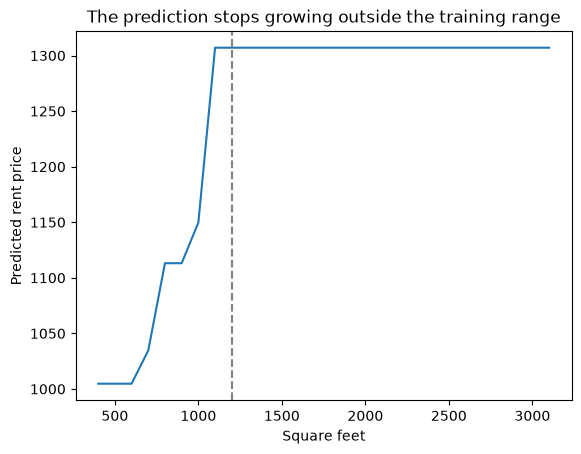

In [29]:
# we take one apartment and change only its size
apartment = X_test.iloc[[0]]
sizes = range(400, 3200, 100)
grid = pd.concat([apartment.assign(square_feet=size) for size in sizes])

plt.plot(sizes, limited.predict(grid))
plt.axvline(1200, color="grey", linestyle="dashed")
plt.xlabel("Square feet")
plt.ylabel("Predicted rent price")
plt.title("The prediction stops growing outside the training range")
plt.show()

The dashed line marks the largest apartment that the model saw during training, and beyond that line the prediction is a flat line, exactly as with random forest.

### How the model combines the trees

AdaBoost does not average the trees when it predicts a number. It sorts the predictions of the trees from the smallest to the largest, it adds up the weights of the trees in that order, and it returns the prediction of the first tree that takes the accumulated weight above half of the total. This is a weighted median, so the answer of the model is always the answer of one of its trees.

In [30]:
# the predictions of each tree in the ensemble
predictions = np.array([tree.predict(apartment.to_numpy())[0] for tree in ada.estimators_])

# the weights of each tree in the ensemble
weights = ada.estimator_weights_[:len(predictions)]

# sort the predictions in ascending order
order = np.argsort(predictions)

# accumulate the weights
accumulated = np.cumsum(weights[order]) / weights[order].sum()
chosen = (accumulated >= 0.5).argmax()

print(f"prediction of the model: {ada.predict(apartment)[0]:.2f}")
print(f"tree selected by the weighted median: {predictions[order][chosen]:.2f}")
print(f"average of the trees: {predictions.mean():.2f}")

prediction of the model: 1392.06
tree selected by the weighted median: 1392.06
average of the trees: 1434.64


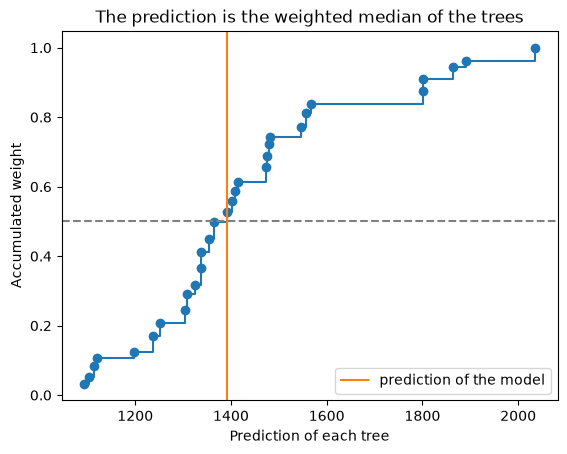

In [31]:
plt.step(predictions[order], accumulated, where="post", marker="o")
plt.axhline(0.5, color="grey", linestyle="dashed")
plt.axvline(predictions[order][chosen], color="C1", label="prediction of the model")
plt.xlabel("Prediction of each tree")
plt.ylabel("Accumulated weight")
plt.title("The prediction is the weighted median of the trees")
plt.legend()
plt.show()

In [32]:
# because the model returns the value of one tree, the predictions are still a small set of values
# we have less unique prediction values than unique rent values

len(pd.unique(ada.predict(X_test))), len(y_test)

(1084, 29946)